In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns


cancer = pd.read_csv("Breast_cancer_dataset.csv")
display(cancer.head())


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [36]:
cancer.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

In [37]:
#How many rows and columns does the dataset have using .shape[]
print("Number of rows:", cancer.shape[0])
print("Number of columns:", cancer.shape[1])

Number of rows: 569
Number of columns: 33


In [38]:
#Finding the number of null cells in each column
total_rows=cancer.shape[0]
null_counts = {}
for i in range(len(cancer.columns)):
    col = cancer.columns[i]
    total_nonnull_cells = cancer[col].count()
    null_cells = total_rows - total_nonnull_cells
    null_counts[col] = null_cells
    print(f"{col}: {null_cells}")

id: 0
diagnosis: 0
radius_mean: 0
texture_mean: 0
perimeter_mean: 0
area_mean: 0
smoothness_mean: 0
compactness_mean: 0
concavity_mean: 0
concave points_mean: 0
symmetry_mean: 0
fractal_dimension_mean: 0
radius_se: 0
texture_se: 0
perimeter_se: 0
area_se: 0
smoothness_se: 0
compactness_se: 0
concavity_se: 0
concave points_se: 0
symmetry_se: 0
fractal_dimension_se: 0
radius_worst: 0
texture_worst: 0
perimeter_worst: 0
area_worst: 0
smoothness_worst: 0
compactness_worst: 0
concavity_worst: 0
concave points_worst: 0
symmetry_worst: 0
fractal_dimension_worst: 0
Unnamed: 32: 569


In [39]:
print(cancer.duplicated().sum())

0


In [40]:
#Finding different categories and their counts for the object data types
categorical_cols = []
numerical_cols = []
for col in cancer.columns:
  if cancer[col].dtype == 'object':
    print(f"Value counts for {col}:\n{cancer[col].value_counts()}\n")
    categorical_cols.append(col)
  else:
    numerical_cols.append(col)
print('numerical columns:',numerical_cols)
print('categorical columns:',categorical_cols)

numerical columns: ['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']
categorical columns: []


In [41]:
#Check zeros in numeric columns
for col in cancer.columns:
    if cancer[col].dtype != 'object':
        zero_count = (cancer[col] == 0).sum()
        print(col, ":", zero_count)

id : 0
diagnosis : 0
radius_mean : 0
texture_mean : 0
perimeter_mean : 0
area_mean : 0
smoothness_mean : 0
compactness_mean : 0
concavity_mean : 13
concave points_mean : 13
symmetry_mean : 0
fractal_dimension_mean : 0
radius_se : 0
texture_se : 0
perimeter_se : 0
area_se : 0
smoothness_se : 0
compactness_se : 0
concavity_se : 13
concave points_se : 13
symmetry_se : 0
fractal_dimension_se : 0
radius_worst : 0
texture_worst : 0
perimeter_worst : 0
area_worst : 0
smoothness_worst : 0
compactness_worst : 0
concavity_worst : 13
concave points_worst : 13
symmetry_worst : 0
fractal_dimension_worst : 0
Unnamed: 32 : 0


In [42]:
# Detect possible outliers in numeric columns
numeric_cancer = cancer.select_dtypes(include="number")

for col in numeric_cancer.columns:
    mean = numeric_cancer[col].mean()
    std = numeric_cancer[col].std()

    if std > 0:
        outliers = ((numeric_cancer[col] - mean).abs() > 3 * std).sum()
        print(col, ":", outliers, "possible outliers")

id : 11 possible outliers
radius_mean : 5 possible outliers
texture_mean : 4 possible outliers
perimeter_mean : 7 possible outliers
area_mean : 8 possible outliers
smoothness_mean : 5 possible outliers
compactness_mean : 9 possible outliers
concavity_mean : 9 possible outliers
concave points_mean : 6 possible outliers
symmetry_mean : 5 possible outliers
fractal_dimension_mean : 7 possible outliers
radius_se : 7 possible outliers
texture_se : 9 possible outliers
perimeter_se : 8 possible outliers
area_se : 6 possible outliers
smoothness_se : 7 possible outliers
compactness_se : 12 possible outliers
concavity_se : 6 possible outliers
concave points_se : 6 possible outliers
symmetry_se : 11 possible outliers
fractal_dimension_se : 10 possible outliers
radius_worst : 6 possible outliers
texture_worst : 4 possible outliers
perimeter_worst : 6 possible outliers
area_worst : 10 possible outliers
smoothness_worst : 3 possible outliers
compactness_worst : 10 possible outliers
concavity_worst : 

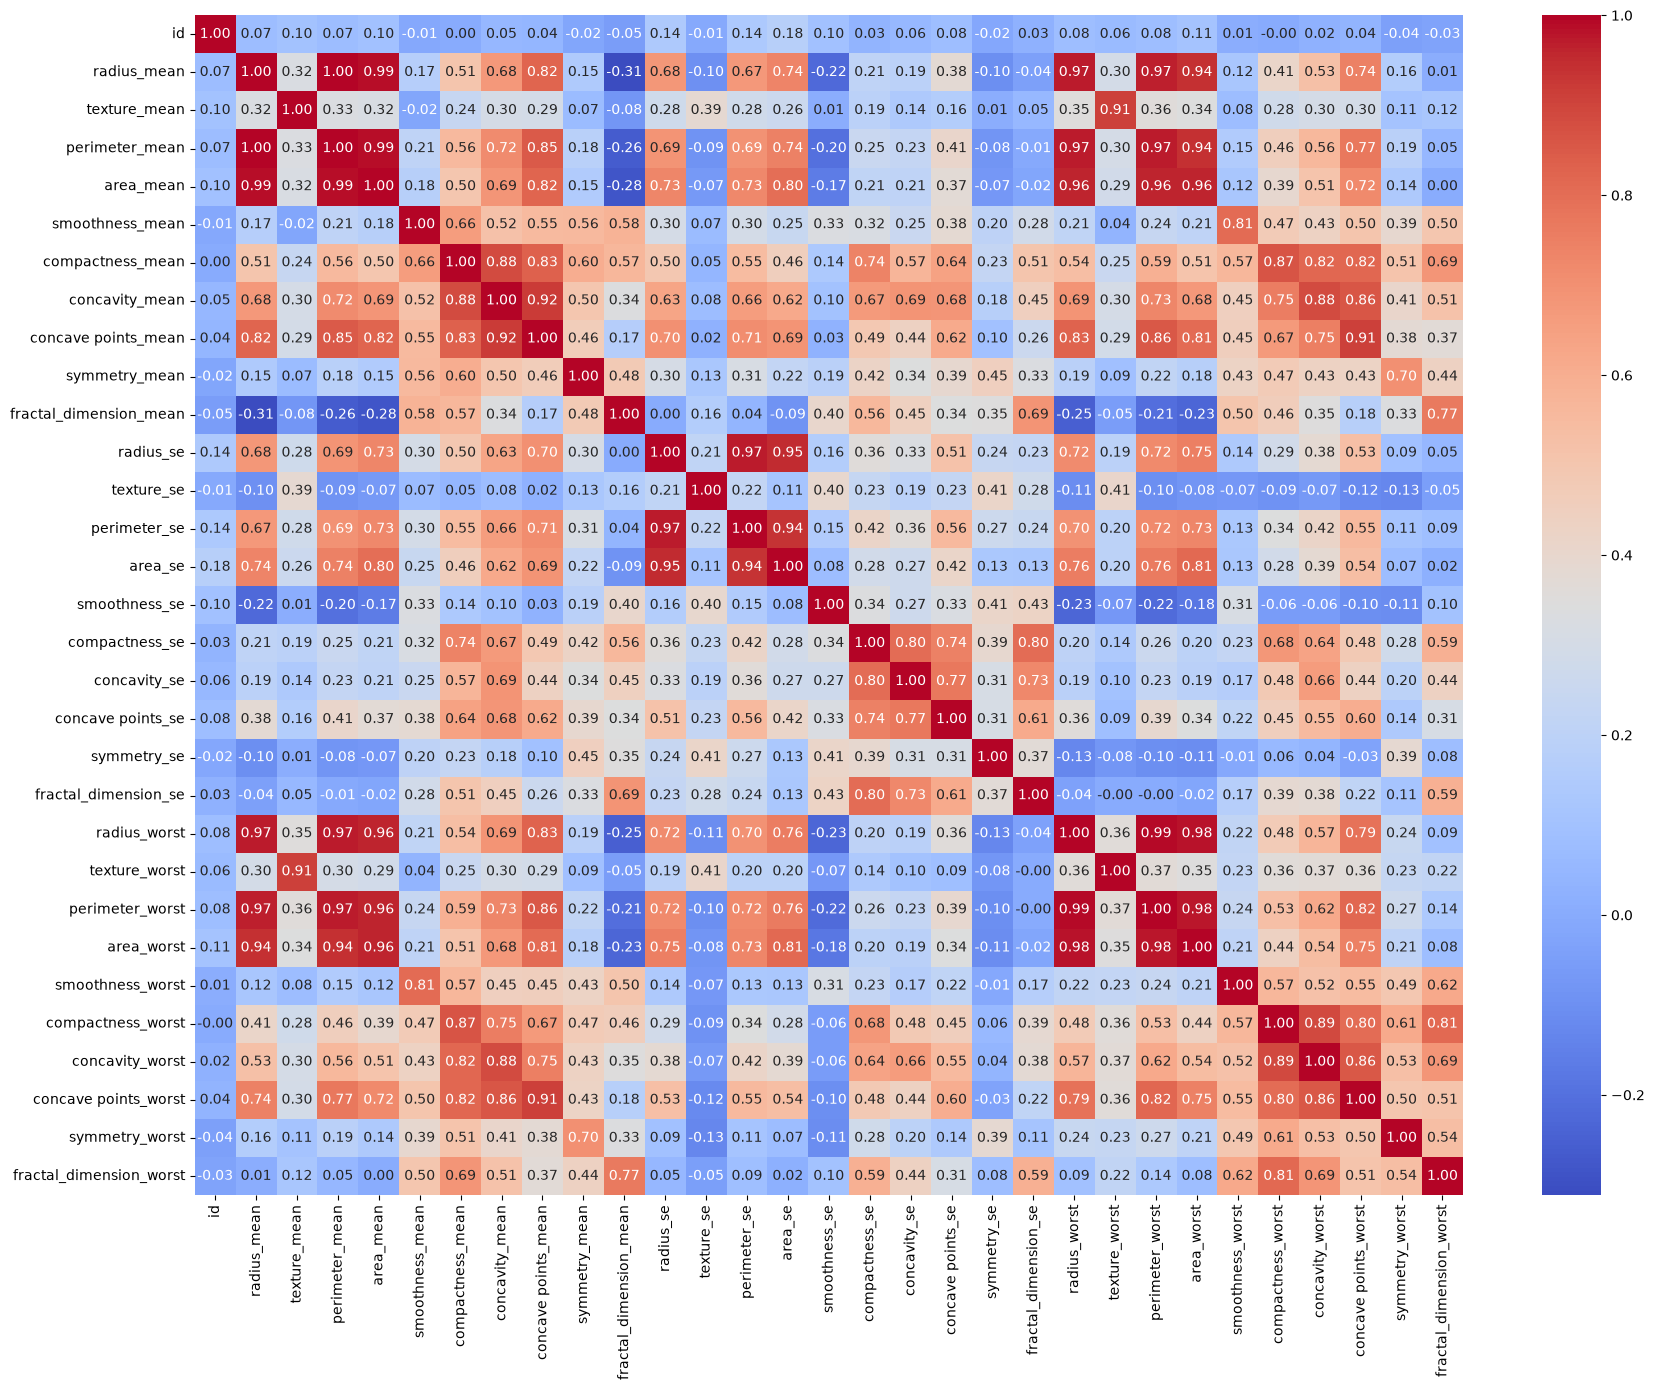

In [43]:


# Remove the completely empty column first
cancer = cancer.drop(columns=["Unnamed: 32"], errors="ignore")

# Replace infinite values and remove any remaining rows with missing values
cancer = cancer.replace([np.inf, -np.inf], np.nan)
cancer = cancer.dropna()

# Keep numeric columns for the correlation heatmap
numeric_cancer = cancer.select_dtypes(include="number")
corr_matrix = numeric_cancer.corr()

plt.figure(figsize=(18, 14))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.tight_layout()
plt.show()


In [44]:
# Convert diagnosis once: B = 0 (benign), M = 1 (malignant)
raw_diagnosis = cancer["diagnosis"]
if not pd.api.types.is_numeric_dtype(raw_diagnosis):
    clean_diagnosis = raw_diagnosis.astype(str).str.strip().str.upper()
    raw_diagnosis = clean_diagnosis.map({"B": 0, "M": 1})
    if raw_diagnosis.isna().any():
        raise ValueError("Unrecognized diagnosis labels: " + repr(clean_diagnosis[raw_diagnosis.isna()].unique()))

cancer["diagnosis"] = pd.to_numeric(raw_diagnosis, errors="raise").astype(int)
if not set(cancer["diagnosis"].unique()).issubset({0, 1}):
    raise ValueError("Diagnosis must be encoded as 0 (benign) or 1 (malignant).")

numeric_cancer = cancer.select_dtypes(include="number")
numeric_cancer.corr()["diagnosis"].sort_values(ascending=False)


diagnosis                  1.000000
concave points_worst       0.793566
perimeter_worst            0.782914
concave points_mean        0.776614
radius_worst               0.776454
perimeter_mean             0.742636
area_worst                 0.733825
radius_mean                0.730029
area_mean                  0.708984
concavity_mean             0.696360
concavity_worst            0.659610
compactness_mean           0.596534
compactness_worst          0.590998
radius_se                  0.567134
perimeter_se               0.556141
area_se                    0.548236
texture_worst              0.456903
smoothness_worst           0.421465
symmetry_worst             0.416294
texture_mean               0.415185
concave points_se          0.408042
smoothness_mean            0.358560
symmetry_mean              0.330499
fractal_dimension_worst    0.323872
compactness_se             0.292999
concavity_se               0.253730
fractal_dimension_se       0.077972
id                         0

In [45]:
# Keep the label in the combined table for stratified splitting.
# Remove only the record ID; do not select features using the full dataset labels.
cancer_new = cancer.drop(columns=["id", "Unnamed: 32"], errors="ignore").copy()

print("Diagnosis counts (0 = benign, 1 = malignant):")
print(cancer_new["diagnosis"].value_counts().sort_index())
print("Input measurements:", cancer_new.drop(columns="diagnosis").shape[1])


Diagnosis counts (0 = benign, 1 = malignant):
diagnosis
0    357
1    212
Name: count, dtype: int64
Input measurements: 30


In [46]:
%pip install scikit-learn

   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.3 MB 1.9 MB/s eta 0:00:05
   ------- -------------------------------- 1.6/8.3 MB 3.2 MB/s eta 0:00:03
   ------------ --------------------------- 2.6/8.3 MB 3.9 MB/s eta 0:00:02
   ----------------- ---------------------- 3.7/8.3 MB 4.1 MB/s eta 0:00:02
   --------------------- ------------------ 4.5/8.3 MB 4.2 MB/s eta 0:00:01
   -------------------------- ------------- 5.5/8.3 MB 4.1 MB/s eta 0:00:01
   ------------------------------ --------- 6.3/8.3 MB 4.2 MB/s eta 0:00:01
   ---------------------------------- ----- 7.1/8.3 MB 4.1 MB/s eta 0:00:01
   ---------------------------------------  8.1/8.3 MB 4.2 MB/s eta 0:00:01
   ---------------------------------------- 8.3/8.3 MB 4.1 MB/s  0:00:02

   -------- -----------------------

In [47]:
# Split into training, validation, and test sets
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
import pickle

X = cancer_new.drop(columns=["diagnosis"]).copy()
y = cancer_new["diagnosis"].astype(int).copy()

# Replace infinities with missing values before splitting
X = X.replace([np.inf, -np.inf], np.nan)

# 80% train+validation, 20% test
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, random_state=10, stratify=y
)

# 70% train, 10% validation, 20% test
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.125,
    random_state=10, stratify=y_train_val
)

feature_columns = X_train.columns

# Fit imputer on training only; apply it to all partitions
imputer = SimpleImputer(strategy="median")
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=feature_columns)
X_val = pd.DataFrame(imputer.transform(X_val), columns=feature_columns)
X_test = pd.DataFrame(imputer.transform(X_test), columns=feature_columns)

# Fit scaler on training only; apply it to validation and test
scaler = StandardScaler()
training_dataset = pd.DataFrame(scaler.fit_transform(X_train), columns=feature_columns)
validation_dataset = pd.DataFrame(scaler.transform(X_val), columns=feature_columns)
testing_dataset = pd.DataFrame(scaler.transform(X_test), columns=feature_columns)

training_labels = y_train.reset_index(drop=True)
validation_labels = y_val.reset_index(drop=True)
testing_labels = y_test.reset_index(drop=True)

# Save processed splits and fitted preprocessing objects
training_dataset.to_csv("cancer_training_data.csv", index=False)
validation_dataset.to_csv("cancer_validation_data.csv", index=False)
testing_dataset.to_csv("cancer_testing_data.csv", index=False)
training_labels.to_csv("cancer_training_labels.csv", index=False)
validation_labels.to_csv("cancer_validation_labels.csv", index=False)
testing_labels.to_csv("cancer_testing_labels.csv", index=False)
with open("cancer_imputer_scaler.pkl", "wb") as f:
    pickle.dump({"imputer": imputer, "scaler": scaler, "columns": list(feature_columns)}, f)

print("Train:", training_dataset.shape, training_labels.shape)
print("Validation:", validation_dataset.shape, validation_labels.shape)
print("Test:", testing_dataset.shape, testing_labels.shape)


Train: (398, 30) (398,)
Validation: (57, 30) (57,)
Test: (114, 30) (114,)


## Classical and quantum fusion classifiers

Both models use all training records and the same `mean`, `se`, and `worst` feature families. Each family is compressed to four PCA components using training records only. The classical fusion model averages RBF kernels; the quantum fusion model uses a weighted average of exact four-qubit fidelity kernels. Validation F1 selects model settings; the held-out test set is used for the final four metrics.

The quantum circuit is simulated exactly with NumPy: Hadamard state preparation, data-dependent RZ rotations, and nearest-neighbor or all-to-all RZZ rotations. This is a classical statevector simulation of a quantum model, not quantum hardware. Because several quantum settings are compared, treat the single-split test result as exploratory and verify with repeated/nested cross-validation before claiming reliable quantum superiority.

In [49]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

FeatureScaler = StandardScaler

In [50]:
# Use the FULL training split for both models (no 220-row subsample)


FEATURE_GROUPS = {
    "mean": [c for c in training_dataset.columns if c.endswith("_mean")],
    "se": [c for c in training_dataset.columns if c.endswith("_se")],
    "worst": [c for c in training_dataset.columns if c.endswith("_worst")],
}
if any(len(cols) < 4 for cols in FEATURE_GROUPS.values()):
    raise ValueError("Each feature family needs at least four columns for 4-component PCA.")

X_kernel_train_raw = training_dataset.reset_index(drop=True)
y_kernel_train = training_labels.reset_index(drop=True)
train_pc, val_pc, test_pc = {}, {}, {}
pca_models, pc_scalers = {}, {}

for group, cols in FEATURE_GROUPS.items():
    pca = PCA(n_components=4, random_state=10)
    train_scores = pca.fit_transform(X_kernel_train_raw[cols])
    val_scores = pca.transform(validation_dataset[cols])
    test_scores = pca.transform(testing_dataset[cols])

    pc_scaler = FeatureScaler()
    train_pc[group] = pc_scaler.fit_transform(train_scores)
    val_pc[group] = pc_scaler.transform(val_scores)
    test_pc[group] = pc_scaler.transform(test_scores)
    pca_models[group] = pca
    pc_scalers[group] = pc_scaler

print("Fusion feature counts:", {g: len(c) for g, c in FEATURE_GROUPS.items()})
print("Training records used by each model:", len(y_kernel_train))


Fusion feature counts: {'mean': 10, 'se': 10, 'worst': 10}
Training records used by each model: 398


In [51]:
# Classical fusion: tune RBF kernel width and SVM C using validation F1
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.svm import SVC
from sklearn.metrics import f1_score

C_VALUES = [0.01, 0.1, 1, 10, 100, 1000]
GAMMA_VALUES = [0.1, 0.25, 0.5, 1.0]
classical_best = None

for gamma in GAMMA_VALUES:
    K_train = sum(rbf_kernel(train_pc[g], train_pc[g], gamma=gamma) for g in FEATURE_GROUPS) / len(FEATURE_GROUPS)
    K_val = sum(rbf_kernel(val_pc[g], train_pc[g], gamma=gamma) for g in FEATURE_GROUPS) / len(FEATURE_GROUPS)
    for C in C_VALUES:
        candidate = SVC(kernel="precomputed", C=C, class_weight="balanced")
        candidate.fit(K_train, y_kernel_train)
        val_pred = candidate.predict(K_val)
        val_f1 = f1_score(validation_labels, val_pred, zero_division=0)
        if classical_best is None or val_f1 > classical_best["val_f1"]:
            classical_best = {"val_f1": val_f1, "gamma": gamma, "C": C, "model": candidate}

classical_gamma = classical_best["gamma"]
classical_C = classical_best["C"]
classical_model = classical_best["model"]
Kc_test = sum(rbf_kernel(test_pc[g], train_pc[g], gamma=classical_gamma) for g in FEATURE_GROUPS) / len(FEATURE_GROUPS)
classical_test_pred = classical_model.predict(Kc_test)
print("Classical selected gamma:", classical_gamma)
print("Classical selected C:", classical_C)
print("Classical validation F1:", round(classical_best["val_f1"], 4))


Classical selected gamma: 0.1
Classical selected C: 0.1
Classical validation F1: 0.9767


In [52]:
# Quantum fusion: tune circuit and kernel-fusion settings on validation only
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import f1_score
from itertools import combinations, product

N_QUBITS = 4
DIM = 2 ** N_QUBITS
bitstrings = (np.arange(DIM)[:, None] >> np.arange(N_QUBITS)) & 1
z_eigenvalues = 1 - 2 * bitstrings
C_VALUES = [0.01, 0.1, 1, 10, 100, 1000]
ANGLE_MAX_VALUES = [np.pi, 2 * np.pi, 4 * np.pi]
EDGE_MODES = ["linear", "full"]
INTERACTION_STRENGTHS = [0.25, 0.5, 1.0]
WEIGHT_VALUES = [0, 0.25, 0.5, 0.75, 1]
WEIGHT_GRID = [w for w in product(WEIGHT_VALUES, repeat=3) if abs(sum(w) - 1) < 1e-9]

def make_states(angle_rows, edges, interaction_strength):
    states = np.empty((len(angle_rows), DIM), dtype=complex)
    for row_index, x in enumerate(angle_rows):
        phase = np.zeros(DIM, dtype=float)
        # RZ(x_i) phase terms
        for i in range(N_QUBITS):
            phase += x[i] * z_eigenvalues[:, i] / 2
        # RZZ(x_i * x_j) phase terms
        for i, j in edges:
            phase += interaction_strength * x[i] * x[j] * z_eigenvalues[:, i] * z_eigenvalues[:, j] / 2
        states[row_index] = np.exp(-1j * phase) / np.sqrt(DIM)
    return states

def fidelity_kernel(states_a, states_b):
    return np.abs(states_a.conj() @ states_b.T) ** 2

quantum_best = None
for angle_max in ANGLE_MAX_VALUES:
    angle_scalers = {}
    train_angles, val_angles = {}, {}
    for group in FEATURE_GROUPS:
        angle_scalers[group] = MinMaxScaler(feature_range=(0, angle_max), clip=True)
        train_angles[group] = angle_scalers[group].fit_transform(train_pc[group])
        val_angles[group] = angle_scalers[group].transform(val_pc[group])

    for edge_mode in EDGE_MODES:
        edges = [(i, i + 1) for i in range(N_QUBITS - 1)] if edge_mode == "linear" else list(combinations(range(N_QUBITS), 2))
        for interaction_strength in INTERACTION_STRENGTHS:
            train_states, val_states = {}, {}
            for group in FEATURE_GROUPS:
                train_states[group] = make_states(train_angles[group], edges, interaction_strength)
                val_states[group] = make_states(val_angles[group], edges, interaction_strength)

            train_parts = {g: fidelity_kernel(train_states[g], train_states[g]) for g in FEATURE_GROUPS}
            val_parts = {g: fidelity_kernel(val_states[g], train_states[g]) for g in FEATURE_GROUPS}

            for weights_tuple in WEIGHT_GRID:
                weights = dict(zip(FEATURE_GROUPS.keys(), weights_tuple))
                K_train = sum(weights[g] * train_parts[g] for g in FEATURE_GROUPS)
                K_val = sum(weights[g] * val_parts[g] for g in FEATURE_GROUPS)
                for C in C_VALUES:
                    candidate = SVC(kernel="precomputed", C=C, class_weight="balanced")
                    candidate.fit(K_train, y_kernel_train)
                    val_pred = candidate.predict(K_val)
                    val_f1 = f1_score(validation_labels, val_pred, zero_division=0)
                    if quantum_best is None or val_f1 > quantum_best["val_f1"]:
                        quantum_best = {
                            "val_f1": val_f1,
                            "angle_max": angle_max,
                            "edge_mode": edge_mode,
                            "interaction_strength": interaction_strength,
                            "weights": weights,
                            "C": C,
                            "model": candidate,
                        }

# Rebuild only the selected quantum kernels for the untouched test features
angle_max = quantum_best["angle_max"]
edge_mode = quantum_best["edge_mode"]
interaction_strength = quantum_best["interaction_strength"]
weights = quantum_best["weights"]
edges = [(i, i + 1) for i in range(N_QUBITS - 1)] if edge_mode == "linear" else list(combinations(range(N_QUBITS), 2))
Kq_test = np.zeros((len(testing_dataset), len(y_kernel_train)))
for group in FEATURE_GROUPS:
    angle_scaler = MinMaxScaler(feature_range=(0, angle_max), clip=True)
    train_angles = angle_scaler.fit_transform(train_pc[group])
    test_angles = angle_scaler.transform(test_pc[group])
    train_states = make_states(train_angles, edges, interaction_strength)
    test_states = make_states(test_angles, edges, interaction_strength)
    Kq_test += weights[group] * fidelity_kernel(test_states, train_states)

quantum_model = quantum_best["model"]
quantum_test_pred = quantum_model.predict(Kq_test)
print("Quantum validation F1:", round(quantum_best["val_f1"], 4))
print("Quantum selected C:", quantum_best["C"])
print("Quantum angle maximum:", round(float(angle_max), 4))
print("Quantum entanglement:", edge_mode)
print("Quantum interaction strength:", interaction_strength)
print("Quantum fusion weights:", weights)


Quantum validation F1: 1.0
Quantum selected C: 100
Quantum angle maximum: 3.1416
Quantum entanglement: linear
Quantum interaction strength: 0.25
Quantum fusion weights: {'mean': 0, 'se': 0.25, 'worst': 0.75}


In [53]:
# Compare all four metrics on the held-out test set
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []
for name, pred in [
    ("Classical fusion SVM", classical_test_pred),
    ("Quantum fusion SVM", quantum_test_pred),
]:
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(testing_labels, pred),
        "Precision": precision_score(testing_labels, pred, zero_division=0),
        "Recall": recall_score(testing_labels, pred, zero_division=0),
        "F1": f1_score(testing_labels, pred, zero_division=0),
    })

results_table = pd.DataFrame(results).set_index("Model").round(4)
display(results_table)

classical_scores = results_table.loc["Classical fusion SVM"]
quantum_scores = results_table.loc["Quantum fusion SVM"]
metric_names = ["Accuracy", "Precision", "Recall", "F1"]
print("Quantum minus classical:")
print((quantum_scores[metric_names] - classical_scores[metric_names]).round(4))

if quantum_scores["F1"] > classical_scores["F1"]:
    print("Conclusion: quantum fusion had higher test F1 on this split. Check the other metrics and repeat the comparison across multiple stratified splits before claiming a reliable advantage.")
elif quantum_scores["F1"] < classical_scores["F1"]:
    print("Conclusion: classical fusion had higher test F1 on this split. The quantum model did not outperform it by the primary metric.")
else:
    print("Conclusion: the two models had the same test F1 on this split. This split shows no F1 advantage for either model.")


,Accuracy,Precision,Recall,F1
Model,,,,
Classical fusion SVM,0.9474,0.9286,0.9286,0.9286
Quantum fusion SVM,0.9737,0.9535,0.9762,0.9647


Quantum minus classical:
Accuracy     0.0263
Precision    0.0249
Recall       0.0476
F1           0.0361
dtype: float64
Conclusion: quantum fusion had higher test F1 on this split. Check the other metrics and repeat the comparison across multiple stratified splits before claiming a reliable advantage.
